In [3]:
import scanpy as sc
from pathlib import Path

In [ ]:
INDIR = Path.home()/'project/crc-pm/result/latest.h5ad'
adata = sc.read_h5ad(INDIR)
adata_epi = adata[adata.obs['Compartment'] == 'Epithelium']
del adata

In [9]:
adata_epi.obs['man_anno_coarse'].unique()

['Tumor', 'Epithelium']
Categories (2, object): ['Epithelium', 'Tumor']

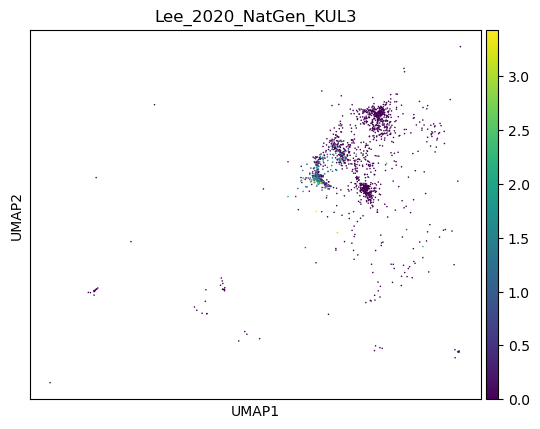

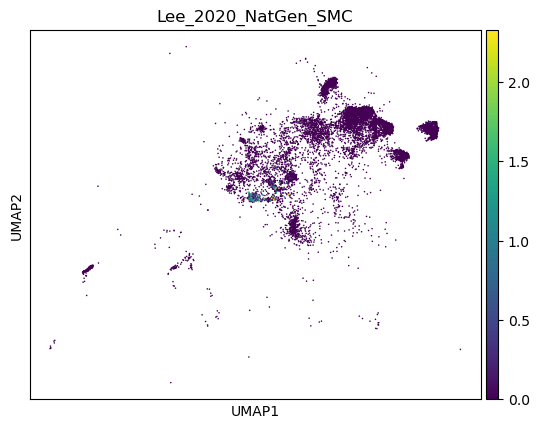

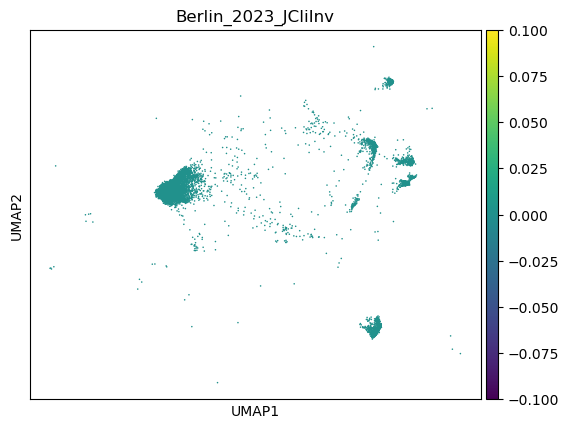

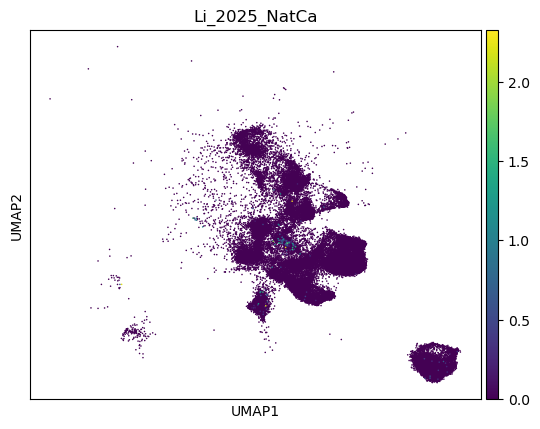

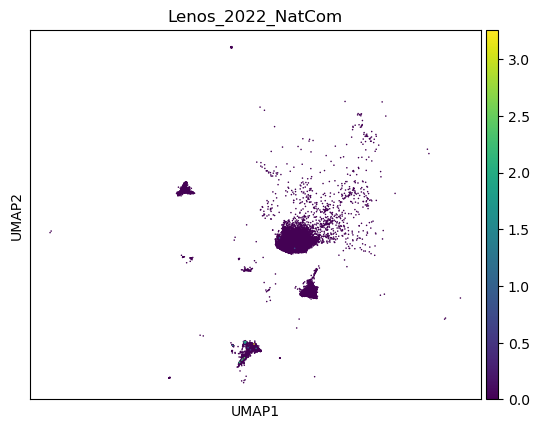

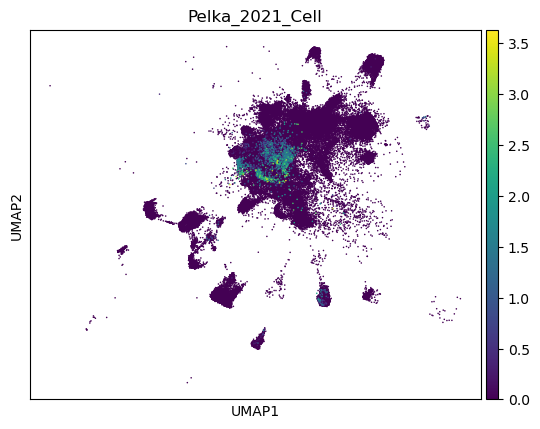

In [12]:
for study in adata_epi.obs['Study'].unique():
    adata = adata_epi[adata_epi.obs['Study'] == study]
    sc.pl.umap(
            adata[adata.obs['man_anno_coarse'] == 'Tumor'],
            layer = "log1p",
            gene_symbols="gene_name",
            color=['CLDN18'],
            size = 5,
            title = f'{study}'
        )

In [15]:
list(adata_epi.obs['scANVI_CellType'].unique())

['Unknown',
 'Cancer TA-like',
 'Cancer Colonocyte-like',
 'Cancer Crypt-like',
 'Tuft',
 'TA progenitor',
 'Colonocyte',
 'Goblet',
 'Colonocyte BEST4',
 'Enteroendocrine',
 'Crypt cell',
 'cDC2',
 'pDC',
 'Cancer Goblet-like',
 'DC mature',
 'Plasma IgA',
 'Cancer BEST4',
 'Cancer cell circulating',
 'Fibroblast S3',
 'Macrophage',
 'Eosinophil',
 'Plasma IgM',
 'Endothelial lymphatic',
 'B cell memory',
 'GC B cell',
 'cDC1']

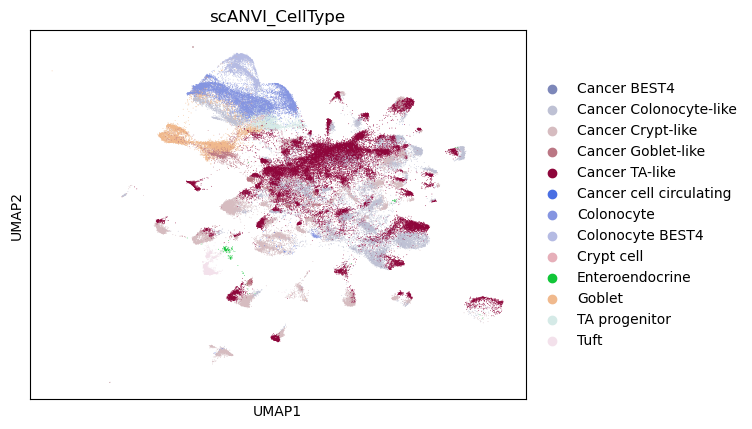

In [16]:
sc.pl.umap(
        adata_epi[adata_epi.obs['scANVI_CellType'].isin([
            'Cancer TA-like',
            'Cancer Colonocyte-like',
            'Cancer Crypt-like',
            'Tuft',
            'TA progenitor',
            'Colonocyte',
            'Goblet',
            'Colonocyte BEST4',
            'Enteroendocrine',
            'Crypt cell',
            'Cancer Goblet-like',
            'Cancer BEST4',
            'Cancer cell circulating',
            ])],
        color='scANVI_CellType',
        gene_symbols="gene_name",
        layer="log1p",
    )